In [323]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings("ignore")

In [324]:
df = pd.read_csv(r"C:\Users\ADMIN\OneDrive\Desktop\Auspify_ML_Internship\Data\Dataset.csv")

In [325]:
df.head(10)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,India,5/1/2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,Germany,9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,India,5/1/2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


In [326]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 8790
Number of Columns: 10


In [327]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [328]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [329]:
print("Duplicate Value:",df.duplicated().sum())

Duplicate Value: 0


In [330]:
df.describe(include="all")

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
count,8790,8790,8790,8790,8790,8790,8790.000000,8790,8790,8790
unique,8790,2,8787,4528,86,1713,NaN,14,220,513
top,s1,Movie,9-Feb,Not Given,United States,1/1/2020,NaN,TV-MA,1 Season,"Dramas, International Movies"
freq,1,6126,2,2588,3240,110,NaN,3205,1791,362
mean,NaN,NaN,NaN,NaN,NaN,NaN,2014.183163,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,8.825466,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN


## 2. Categorical Data Analysis

In this section, we will analyze categorical columns
to understand the distribution of Netflix content.

In [331]:
df["type"].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

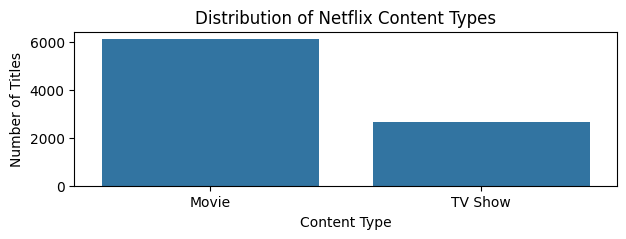

In [332]:
plt.figure(figsize=(7,2))

sns.countplot(data=df,x="type")

plt.title('Distribution of Netflix Content Types')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.show()

In [333]:
df["rating"].value_counts().head(10)

rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64

In [334]:
df["listed_in"].value_counts().head(10)

listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            219
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, International Movies, Romantic Movies       180
Name: count, dtype: int64

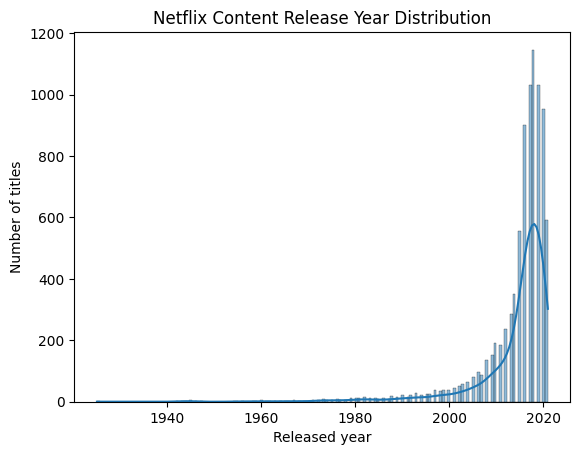

In [335]:
plt.Figure(figsize=(10,5))
sns.histplot(data=df,x="release_year",kde=True)
plt.title("Netflix Content Release Year Distribution")
plt.xlabel("Released year")
plt.ylabel("Number of titles")
plt.show( )

## 3. Feature Engineering

In this section, we will prepare relevant content
attributes for building our recommendation system.

In [336]:
features = [
    'title',
    'type',
    'director',
    'country',
    'rating',
    'listed_in'
]

df[features].head(10)

,title,type,director,country,rating,listed_in
0,Dick Johnson Is Dead,Movie,Kirsten Johnson,United States,PG-13,Documentaries
1,Ganglands,TV Show,Julien Leclercq,France,TV-MA,"Crime TV Shows, International TV Shows, TV Act..."
2,Midnight Mass,TV Show,Mike Flanagan,United States,TV-MA,"TV Dramas, TV Horror, TV Mysteries"
3,Confessions of an Invisible Girl,Movie,Bruno Garotti,Brazil,TV-PG,"Children & Family Movies, Comedies"
4,Sankofa,Movie,Haile Gerima,United States,TV-MA,"Dramas, Independent Movies, International Movies"
5,The Great British Baking Show,TV Show,Andy Devonshire,United Kingdom,TV-14,"British TV Shows, Reality TV"
6,The Starling,Movie,Theodore Melfi,United States,PG-13,"Comedies, Dramas"
7,Motu Patlu in the Game of Zones,Movie,Suhas Kadav,India,TV-Y7,"Children & Family Movies, Comedies, Music & Mu..."
8,Je Suis Karl,Movie,Christian Schwochow,Germany,TV-MA,"Dramas, International Movies"
9,Motu Patlu in Wonderland,Movie,Suhas Kadav,India,TV-Y7,"Children & Family Movies, Music & Musicals"


In [337]:
for col in features:
    if col != 'title':
        print(f"\n{col}")
        print(df[col].value_counts().head(5))


type
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

director
director
Not Given                 2588
Rajiv Chilaka               20
Alastair Fothergill         18
Raúl Campos, Jan Suter      18
Suhas Kadav                 16
Name: count, dtype: int64

country
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64

rating
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Name: count, dtype: int64

listed_in
listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Name: count, dtype: int64


In [338]:
missing_values = ['Unknown', 'Not Given', 'NaN', '']

for col in features:
    count = df[col].astype(str).str.strip().isin(missing_values).sum()
    print(f"{col}: {count}")

title: 1
type: 0
director: 2588
country: 287
rating: 0
listed_in: 0


In [339]:
df[df['title'].astype(str).str.strip().isin(['', 'NaN', 'Unknown', 'Not Given'])]

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
1336,s1468,Movie,Unknown,Jaume Collet-Serra,United Kingdom,1/1/2021,2011,PG-13,113 min,"Action & Adventure, Thrillers"


In [340]:
df['title'].is_unique

False

In [341]:
for col in ['type', 'rating']:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())


Unique values in type:
['Movie' 'TV Show']

Unique values in rating:
['PG-13' 'TV-MA' 'TV-PG' 'TV-14' 'TV-Y7' 'TV-Y' 'PG' 'TV-G' 'R' 'G'
 'NC-17' 'NR' 'TV-Y7-FV' 'UR']


## 4. Data Cleaning

In this section, we will handle invalid title values
and prepare the dataset for feature engineering.

In [342]:
df_clean = df.copy()

In [343]:
df_clean['title'] = df_clean['title'].str.strip()

df_clean = df_clean[
    df_clean['title'].ne('Unknown')  # ne means not equal
].copy()

In [344]:
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("Remaining Unknown Titles:",
      (df_clean['title'] == 'Unknown').sum())

Original Dataset Shape: (8790, 10)
Cleaned Dataset Shape: (8789, 10)
Remaining Unknown Titles: 0


In [345]:
df_clean['director'] = df_clean['director'].replace('Not Given', '')

df_clean['country'] = df_clean['country'].replace('Not Given', '')

In [346]:
print("Missing Director:",(df_clean['director'] == '').sum())

print("Missing Country:",(df_clean['country'] == '').sum())

print("Dataset Shape:", df_clean.shape)

Missing Director: 2588
Missing Country: 287
Dataset Shape: (8789, 10)


In [347]:
duplicate_titles = df_clean[df_clean['title'].duplicated(keep=False)].sort_values('title')

duplicate_titles[['show_id', 'title', 'type', 'release_year']].head(20)

,show_id,title,type,release_year
2925,s3963,15-Aug,Movie,2019
4261,s5967,15-Aug,Movie,2019
3285,s4523,22-Jul,Movie,2018
4260,s5966,22-Jul,Movie,2018
393,s3997,9-Feb,TV Show,2018
537,s5965,9-Feb,TV Show,2018
2590,s3372,Consequences,Movie,2014
4718,s6530,Consequences,Movie,2014


In [348]:
duplicate_titles = df_clean[
    df_clean['title'].duplicated(keep=False)
].sort_values('title')

duplicate_titles

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
393,s3997,TV Show,9-Feb,,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
2590,s3372,Movie,Consequences,Ozan Açıktan,Turkey,10/25/2019,2014,TV-MA,106 min,"Dramas, International Movies, Thrillers"
4718,s6530,Movie,Consequences,Ozan Açıktan,Turkey,10/25/2019,2014,TV-MA,106 min,"Dramas, International Movies, Thrillers"


In [349]:
duplicate_titles = df_clean[
    df_clean['title'].duplicated(keep=False)
].sort_values('title')

duplicate_titles

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
393,s3997,TV Show,9-Feb,,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
2590,s3372,Movie,Consequences,Ozan Açıktan,Turkey,10/25/2019,2014,TV-MA,106 min,"Dramas, International Movies, Thrillers"
4718,s6530,Movie,Consequences,Ozan Açıktan,Turkey,10/25/2019,2014,TV-MA,106 min,"Dramas, International Movies, Thrillers"


In [350]:
print(
    "Total duplicate title rows:",
    df_clean['title'].duplicated().sum()
)

print(
    "Number of repeated title groups:",
    (df_clean['title'].value_counts() > 1).sum()
)

Total duplicate title rows: 4
Number of repeated title groups: 4


In [351]:
print(
    "Exact duplicate records:",
    df_clean.duplicated().sum()
)

Exact duplicate records: 0


## 5. Duplicate Content Handling

We identified four repeated title groups with identical
content attributes but different show IDs.

To avoid duplicate recommendations, we will retain
one record from each group in our modeling dataset.

In [352]:
content_columns = [
    'type',
    'title',
    'director',
    'country',
    'date_added',
    'release_year',
    'rating',
    'duration',
    'listed_in'
]

In [353]:
df_model = df_clean.drop_duplicates(
    subset=content_columns,
    keep='first'
).copy()

In [354]:
print("Original Cleaned Dataset:", df_clean.shape)
print("Modeling Dataset:", df_model.shape)

print(
    "Duplicate Content Records:",
    df_model.duplicated(subset=content_columns).sum()
)

Original Cleaned Dataset: (8789, 10)
Modeling Dataset: (8785, 10)
Duplicate Content Records: 0


In [355]:
selected_features = [
    'title', 'type', 'director', 'country', 'rating', 'listed_in'
]

In [356]:
def clean_text(text):
    text = str(text).lower()
    text = text.replace('&', ' ')
    text = text.replace(',', ' ')
    text = ' '.join(text.split())
    return text

for col in selected_features:
    df_model[col] = df_model[col].apply(clean_text)

df_model['combined_features'] = (
    df_model[selected_features].agg(' '.join, axis=1)
)

In [357]:
df_model[['title', 'combined_features']].head(10)

,title,combined_features
0,dick johnson is dead,dick johnson is dead movie kirsten johnson uni...
1,ganglands,ganglands tv show julien leclercq france tv-ma...
2,midnight mass,midnight mass tv show mike flanagan united sta...
3,confessions of an invisible girl,confessions of an invisible girl movie bruno g...
4,sankofa,sankofa movie haile gerima united states tv-ma...
5,the great british baking show,the great british baking show tv show andy dev...
6,the starling,the starling movie theodore melfi united state...
7,motu patlu in the game of zones,motu patlu in the game of zones movie suhas ka...
8,je suis karl,je suis karl movie christian schwochow germany...
9,motu patlu in wonderland,motu patlu in wonderland movie suhas kadav ind...


In [358]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(
    df_model['combined_features']
)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (8785, 43146)


In [359]:
print("Number of Netflix titles:", tfidf_matrix.shape[0])
print("Total vocabulary size:", tfidf_matrix.shape[1])
print("Matrix data type:", type(tfidf_matrix))

Number of Netflix titles: 8785
Total vocabulary size: 43146
Matrix data type: <class 'scipy.sparse._csr.csr_matrix'>


In [360]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_sim = cosine_similarity(tfidf_matrix)

print("Cosine Similarity Shape:", cosine_sim.shape)

Cosine Similarity Shape: (8785, 8785)


In [361]:
df_model = df_model.reset_index(drop=True)

In [362]:
def recommend_movies(title, cosine_sim, df):

    indices = pd.Series(df.index, index=df['title'])

    title = title.strip().lower()

    if title not in indices.index:
        return f"'{title}' not found in the dataset."

    idx = indices[title]

    similarity_scores = list(enumerate(cosine_sim[idx]))

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    similarity_scores = [
        item for item in similarity_scores
        if item[0] != idx
    ][:10]

    movie_indices = [item[0] for item in similarity_scores]
    scores = [item[1] for item in similarity_scores]

    recommendations = df.iloc[movie_indices][
        ['title', 'type', 'listed_in']
    ].copy()

    recommendations['similarity_score'] = scores

    return recommendations

In [363]:
recommend_movies('The Starling', cosine_sim, df_model)

,title,type,listed_in,similarity_score
872,love jones,movie,comedies dramas independent movies,0.249189
2958,finally found someone,movie,international movies romantic movies,0.200364
1399,just the way you are,movie,international movies romantic movies,0.186269
2940,vince and kath and james,movie,international movies romantic movies,0.179287
4753,dean,movie,comedies dramas independent movies,0.173865
6050,the break-up,movie,comedies dramas romantic movies,0.170967
2944,5 flights up,movie,comedies dramas independent movies,0.168688
729,mother's day,movie,comedies dramas,0.166318
6053,the bucket list,movie,comedies dramas,0.165387
6017,the american president,movie,comedies dramas romantic movies,0.163176


# Inspect


In [364]:
df_model[
    df_model['title'] == 'The Starling'
][
    ['title', 'type', 'director', 'country', 'rating', 'listed_in',
     'combined_features']
]

,title,type,director,country,rating,listed_in,combined_features


In [365]:
recommended_titles = [
    'Love Jones',
    'Vince and Kath and James',
    'Finally Found Someone',
    'Just The Way You Are'
]

df_model[
    df_model['title'].isin(recommended_titles)
][
    ['title', 'type', 'director', 'country', 'rating', 'listed_in']
]

,title,type,director,country,rating,listed_in


In [366]:
df_model['director'] = (
    df_model['director']
    .str.replace(' ', '_', regex=False)
)

In [367]:
df_model['combined_features'] = (
    df_model[selected_features].agg(' '.join, axis=1)
)

In [368]:
df_model[['title', 'director', 'combined_features']].head(10)

,title,director,combined_features
0,dick johnson is dead,kirsten_johnson,dick johnson is dead movie kirsten_johnson uni...
1,ganglands,julien_leclercq,ganglands tv show julien_leclercq france tv-ma...
2,midnight mass,mike_flanagan,midnight mass tv show mike_flanagan united sta...
3,confessions of an invisible girl,bruno_garotti,confessions of an invisible girl movie bruno_g...
4,sankofa,haile_gerima,sankofa movie haile_gerima united states tv-ma...
5,the great british baking show,andy_devonshire,the great british baking show tv show andy_dev...
6,the starling,theodore_melfi,the starling movie theodore_melfi united state...
7,motu patlu in the game of zones,suhas_kadav,motu patlu in the game of zones movie suhas_ka...
8,je suis karl,christian_schwochow,je suis karl movie christian_schwochow germany...
9,motu patlu in wonderland,suhas_kadav,motu patlu in wonderland movie suhas_kadav ind...


In [369]:
tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(
    df_model['combined_features']
)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (8785, 39362)


In [370]:
cosine_sim = cosine_similarity(tfidf_matrix)

print("Cosine Similarity Shape:", cosine_sim.shape)

Cosine Similarity Shape: (8785, 8785)


In [371]:
df_model.loc[
    df_model['title'].isin([
        'The Starling',
        'Love Jones',
        'Vince and Kath and James'
    ]),
    ['title', 'director', 'combined_features']
]

,title,director,combined_features


In [372]:
print("Theodore Melfi:", 'theodore_melfi' in tfidf.vocabulary_)
print("Theodore Witcher:", 'theodore_witcher' in tfidf.vocabulary_)
print("Theodore Boborol:", 'theodore_boborol' in tfidf.vocabulary_)

Theodore Melfi: True
Theodore Witcher: True
Theodore Boborol: True


In [373]:
print(cosine_sim[6, 872])

0.06516507431338339


In [374]:
recommend_movies('The Starling', cosine_sim, df_model)

,title,type,listed_in,similarity_score
6050,the break-up,movie,comedies dramas romantic movies,0.213527
729,mother's day,movie,comedies dramas,0.205843
887,the meddler,movie,comedies dramas independent movies,0.201531
2944,5 flights up,movie,comedies dramas independent movies,0.201531
3146,dumplin',movie,comedies dramas independent movies,0.201531
4753,dean,movie,comedies dramas independent movies,0.201531
6053,the bucket list,movie,comedies dramas,0.197307
2089,the half of it,movie,comedies dramas lgbtq movies,0.195473
1186,moxie,movie,comedies dramas music musicals,0.195444
6017,the american president,movie,comedies dramas romantic movies,0.194304


In [375]:
recommend_movies('The Dark Knight', cosine_sim, df_model)


"'the dark knight' not found in the dataset."

In [376]:
recommend_movies('Breaking Bad', cosine_sim, df_model)


,title,type,listed_in,similarity_score
7680,when they see us,tv show,crime tv shows tv dramas,0.566765
6920,dare me,tv show,crime tv shows tv dramas tv thrillers,0.533715
7683,what / if,tv show,tv dramas tv thrillers,0.526666
7304,ozark,tv show,crime tv shows tv dramas tv thrillers,0.523068
7669,designated survivor,tv show,crime tv shows tv dramas tv thrillers,0.455315
7073,the blacklist,tv show,crime tv shows tv dramas tv thrillers,0.455120
7983,somewhere between,tv show,crime tv shows tv dramas tv mysteries,0.444643
8333,american crime,tv show,crime tv shows tv dramas,0.440676
7314,she,tv show,crime tv shows international tv shows tv dramas,0.412234
6871,the sinner,tv show,crime tv shows tv dramas tv mysteries,0.409306


In [377]:
recommend_movies('The Queen', cosine_sim, df_model)

,title,type,listed_in,similarity_score
1141,philomena,movie,dramas independent movies international movies,0.681089
1877,queen,movie,comedies dramas international movies,0.311854
1272,the dig,movie,dramas international movies,0.281249
2529,suffragette,movie,dramas international movies,0.281249
1156,get on up,movie,dramas music musicals,0.273624
3292,the black prince,movie,dramas international movies,0.263468
6171,the iron lady,movie,dramas international movies,0.256853
1481,loving,movie,dramas romantic movies,0.253095
4516,becoming jane,movie,dramas romantic movies,0.246731
2432,the two popes,movie,dramas,0.245186


In [378]:
df_model.loc[
    df_model['title'].isin([
        'Breaking Bad',
        'Dare Me',
        'Ozark',
        'Designated Survivor'
    ]),
    ['title', 'director', 'country', 'rating',
     'listed_in', 'combined_features']
]

,title,director,country,rating,listed_in,combined_features


In [379]:
df_model['combined_features'] = (
    df_model[selected_features].agg(' '.join, axis=1)
)

In [380]:
tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(
    df_model['combined_features']
)

In [381]:
cosine_sim = cosine_similarity(tfidf_matrix)

In [382]:
recommend_movies('Ozark', cosine_sim, df_model)

,title,type,listed_in,similarity_score
7680,when they see us,tv show,crime tv shows tv dramas,0.622534
6920,dare me,tv show,crime tv shows tv dramas tv thrillers,0.586232
7683,what / if,tv show,tv dramas tv thrillers,0.578489
8314,breaking bad,tv show,crime tv shows tv dramas tv thrillers,0.523068
7669,designated survivor,tv show,crime tv shows tv dramas tv thrillers,0.500118
7073,the blacklist,tv show,crime tv shows tv dramas tv thrillers,0.499903
7983,somewhere between,tv show,crime tv shows tv dramas tv mysteries,0.488395
8333,american crime,tv show,crime tv shows tv dramas,0.484039
7314,she,tv show,crime tv shows international tv shows tv dramas,0.452798
6871,the sinner,tv show,crime tv shows tv dramas tv mysteries,0.449582


In [383]:
print("DataFrame shape:", df_model.shape)

print("Ozark exists:",
      df_model['title'].eq('Ozark').any())

print("Matching titles:")
print(
    df_model.loc[
        df_model['title'].str.contains(
            'Ozark', case=False, na=False
        ),
        'title'
    ]
)

DataFrame shape: (8785, 11)
Ozark exists: False
Matching titles:
7304    ozark
Name: title, dtype: object


In [384]:
recommend_movies('Breaking Bad', cosine_sim, df_model)

,title,type,listed_in,similarity_score
7680,when they see us,tv show,crime tv shows tv dramas,0.566765
6920,dare me,tv show,crime tv shows tv dramas tv thrillers,0.533715
7683,what / if,tv show,tv dramas tv thrillers,0.526666
7304,ozark,tv show,crime tv shows tv dramas tv thrillers,0.523068
7669,designated survivor,tv show,crime tv shows tv dramas tv thrillers,0.455315
7073,the blacklist,tv show,crime tv shows tv dramas tv thrillers,0.455120
7983,somewhere between,tv show,crime tv shows tv dramas tv mysteries,0.444643
8333,american crime,tv show,crime tv shows tv dramas,0.440676
7314,she,tv show,crime tv shows international tv shows tv dramas,0.412234
6871,the sinner,tv show,crime tv shows tv dramas tv mysteries,0.409306


In [385]:
print("Input title:", 'Breaking Bad'.lower())

print(
    df_model.loc[
        df_model['title'] == 'breaking bad',
        ['title', 'combined_features']
    ]
)

Input title: breaking bad
             title                                  combined_features
8314  breaking bad  breaking bad tv show  united states tv-ma crim...


In [387]:
title = 'Breaking Bad'

idx = df_model.index[
    df_model['title'] == title.lower()
][0]

print("Input title:", df_model.loc[idx, 'title'])
print("Input index:", idx)
print("Self similarity:", cosine_sim[idx, idx])

Input title: breaking bad
Input index: 8314
Self similarity: 1.0000000000000002
